In [1]:
"""Caltech101_Final_Trainer.ipynb"""

# STEP 1️⃣ — Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# STEP 2️⃣ — Install requirements
!pip install -q kaggle tensorflow matplotlib scikit-learn pandas

# STEP 3️⃣ — Upload kaggle.json (manually)
from google.colab import files
files.upload()  # Upload your kaggle.json file

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Mounted at /content/drive


Saving kaggle.json to kaggle.json


In [2]:
# STEP 4️⃣ — Download and extract Caltech-101
!kaggle datasets download -d imbikramsaha/caltech-101 -p /content/
!unzip -q /content/caltech-101.zip -d /content/dataset

# STEP 5️⃣ — Split dataset (train/validation)
import os, shutil
from pathlib import Path
from sklearn.model_selection import train_test_split

dataset_path = "/content/dataset/caltech-101"
base_dir = Path("/content/caltech_split")
train_dir = base_dir / "train"
val_dir = base_dir / "val"

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

for category in os.listdir(dataset_path):
    cat_path = os.path.join(dataset_path, category)
    if os.path.isdir(cat_path):
        images = [os.path.join(cat_path, f) for f in os.listdir(cat_path) if f.endswith('.jpg')]
        if len(images) < 5:  # skip small folders
            continue
        train_imgs, val_imgs = train_test_split(images, test_size=0.2, random_state=42)

        os.makedirs(train_dir / category, exist_ok=True)
        os.makedirs(val_dir / category, exist_ok=True)

        for img in train_imgs:
            shutil.copy(img, train_dir / category)
        for img in val_imgs:
            shutil.copy(img, val_dir / category)

print("✅ Dataset split complete.")

Dataset URL: https://www.kaggle.com/datasets/imbikramsaha/caltech-101
License(s): CC0-1.0
  0% 0.00/131M [00:00<?, ?B/s]
100% 131M/131M [00:00<00:00, 1.68GB/s]
✅ Dataset split complete.


In [13]:
# STEP 6️⃣ — Build and train model with fine-tuning

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=25, width_shift_range=0.2,
                                   height_shift_range=0.2, zoom_range=0.2, horizontal_flip=True)
val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir, target_size=(224, 224), batch_size=32, class_mode='categorical'
)
val_gen = val_datagen.flow_from_directory(
    val_dir, target_size=(224, 224), batch_size=32, class_mode='categorical'
)

# 🔹 Load MobileNetV2
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))

# 🔹 Freeze most layers, fine-tune last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers[-30:]:
    layer.trainable = True

x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.4)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
out = Dense(train_gen.num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=out)

# 🔹 Compile
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='categorical_crossentropy', metrics=['accuracy'])

# 🔹 Train model (increased epochs)
history = model.fit(train_gen, validation_data=val_gen, epochs=70)
print("✅ Model training complete!")


Found 7280 images belonging to 102 classes.
Found 1864 images belonging to 102 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/70
228/228 ━━━━━━━━━━━━━━━━━━━━ 123s 468ms/step - accuracy: 0.2268 - loss: 3.7937 - val_accuracy: 0.6298 - val_loss: 1.7433
Epoch 2/70
228/228 ━━━━━━━━━━━━━━━━━━━━ 90s 394ms/step - accuracy: 0.6106 - loss: 1.7780 - val_accuracy: 0.8235 - val_loss: 0.7372
Epoch 3/70
228/228 ━━━━━━━━━━━━━━━━━━━━ 90s 396ms/step - accuracy: 0.7740 - loss: 0.9140 - val_accuracy: 0.8788 - val_loss: 0.4600
Epoch 4/70
228/228 ━━━━━━━━━━━━━━━━━━━━ 89s 391ms/step - accuracy: 0.8366 - loss: 0.6381 - val_accuracy: 0.9002 - val_loss: 0.3741
Epoch 5/70
228/228 ━━━━━━━━━━━━━━━━━━━━ 88s 388ms/step - accuracy: 0.8687 - loss: 0.5078 - val_accuracy: 0.9067 - val_loss: 0.3501
Epoch 6/70
228/228 ━━━━━━━━━━━━━━━━━━━━ 92s 402ms/step - accuracy: 0.8976 - loss: 0.3647 - val_accuracy: 0.9211 - val_loss: 0.3247
Epoch 7/70
228/228 ━━━━━━━━━━━━━━━━━━━━ 88s 385ms/step - accuracy: 0.9056 - loss: 0.3319 - val_accuracy: 0.9260 - val_loss: 0.2844
Epoch 8/70
228/228 ━━━━━━━━━━━━━━━━━━━━ 89s 391ms/step - accuracy: 0.9259 - loss: 

In [15]:
# STEP 7️⃣ — Save model and class mapping
import json

model_path = "/content/drive/MyDrive/caltech_model_finetuned.h5"
mapping_path = "/content/drive/MyDrive/class_indices.json"

model.save(model_path)
with open(mapping_path, "w") as f:
    json.dump(train_gen.class_indices, f)

print("💾 Model and class mapping saved to Google Drive.")


💾 Model and class mapping saved to Google Drive.


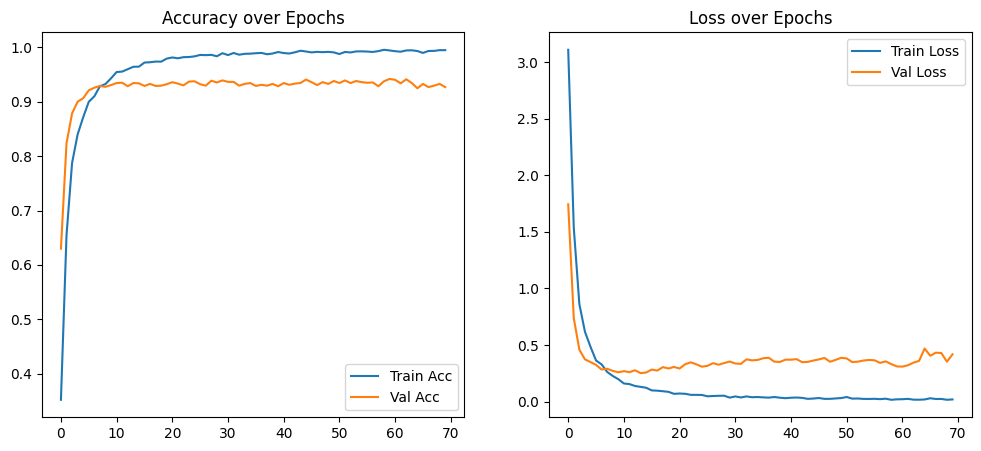

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


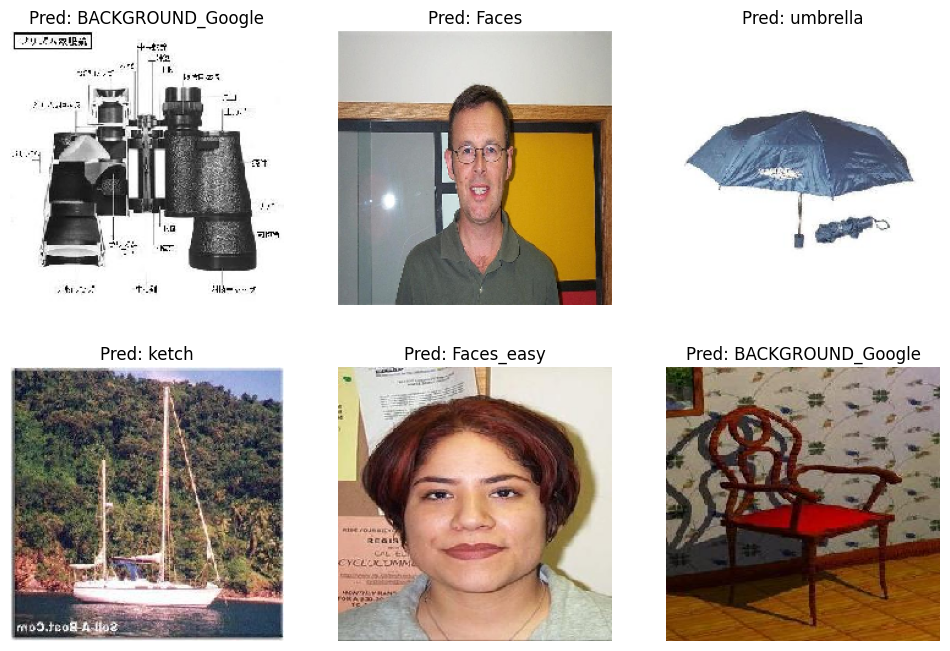

✅ All steps completed successfully.


In [17]:
# STEP 8️⃣ — Evaluate and visualize
import matplotlib.pyplot as plt

acc, val_acc = history.history['accuracy'], history.history['val_accuracy']
loss, val_loss = history.history['loss'], history.history['val_loss']

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(acc, label='Train Acc')
plt.plot(val_acc, label='Val Acc')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1,2,2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.title('Loss over Epochs')
plt.legend()
plt.show()

# STEP 9️⃣ — Test sample predictions
import numpy as np

labels = list(train_gen.class_indices.keys())
x_batch, y_batch = next(val_gen)
preds = model.predict(x_batch)
pred_classes = np.argmax(preds, axis=1)

plt.figure(figsize=(12,8))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(x_batch[i])
    plt.title(f"Pred: {labels[pred_classes[i]]}")
    plt.axis("off")
plt.show()

print("✅ All steps completed successfully.")

59/59 ━━━━━━━━━━━━━━━━━━━━ 12s 132ms/step


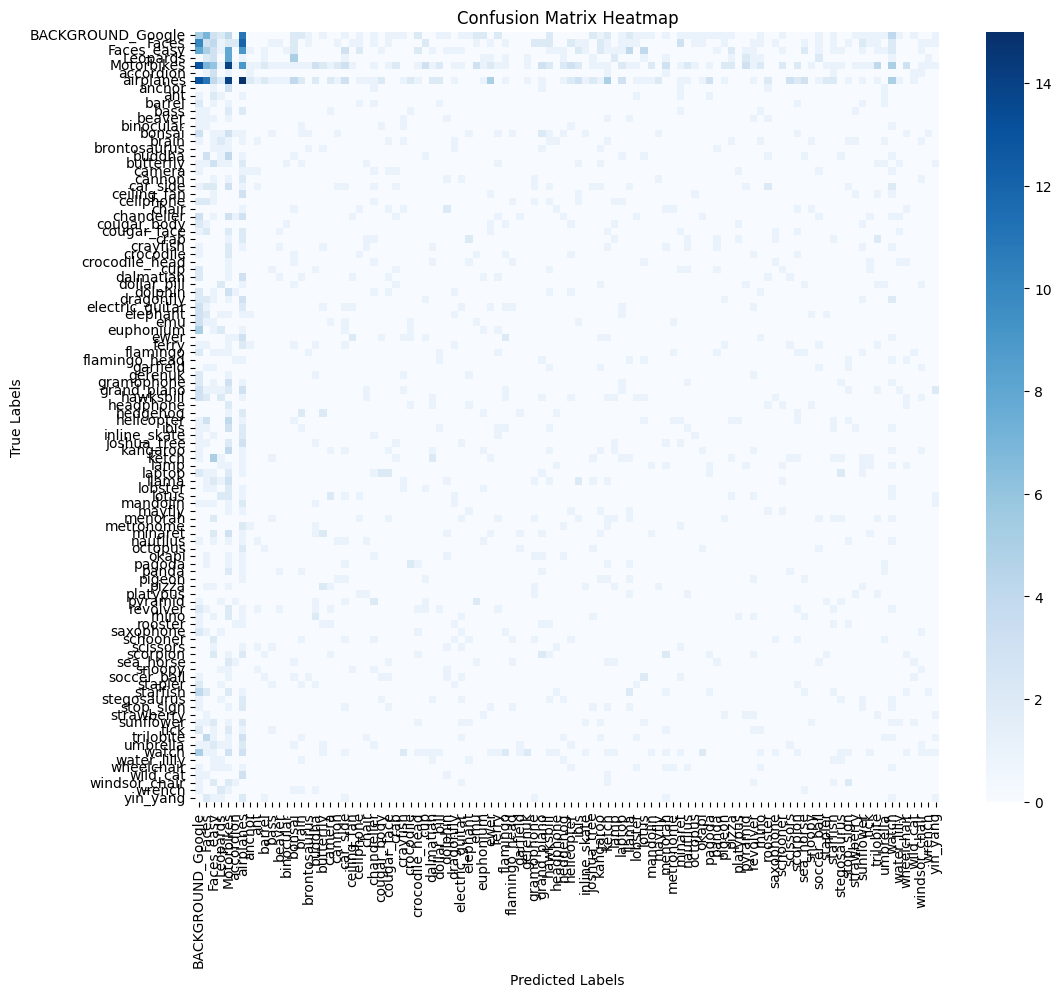

In [18]:
# STEP 9️⃣ — Confusion Matrix + Heatmap + ROC & PR Curves
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize

val_gen.reset()
y_pred = model.predict(val_gen, verbose=1)
y_true = val_gen.classes
y_pred_classes = np.argmax(y_pred, axis=1)
class_labels = list(val_gen.class_indices.keys())

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
plt.title("Confusion Matrix Heatmap")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()



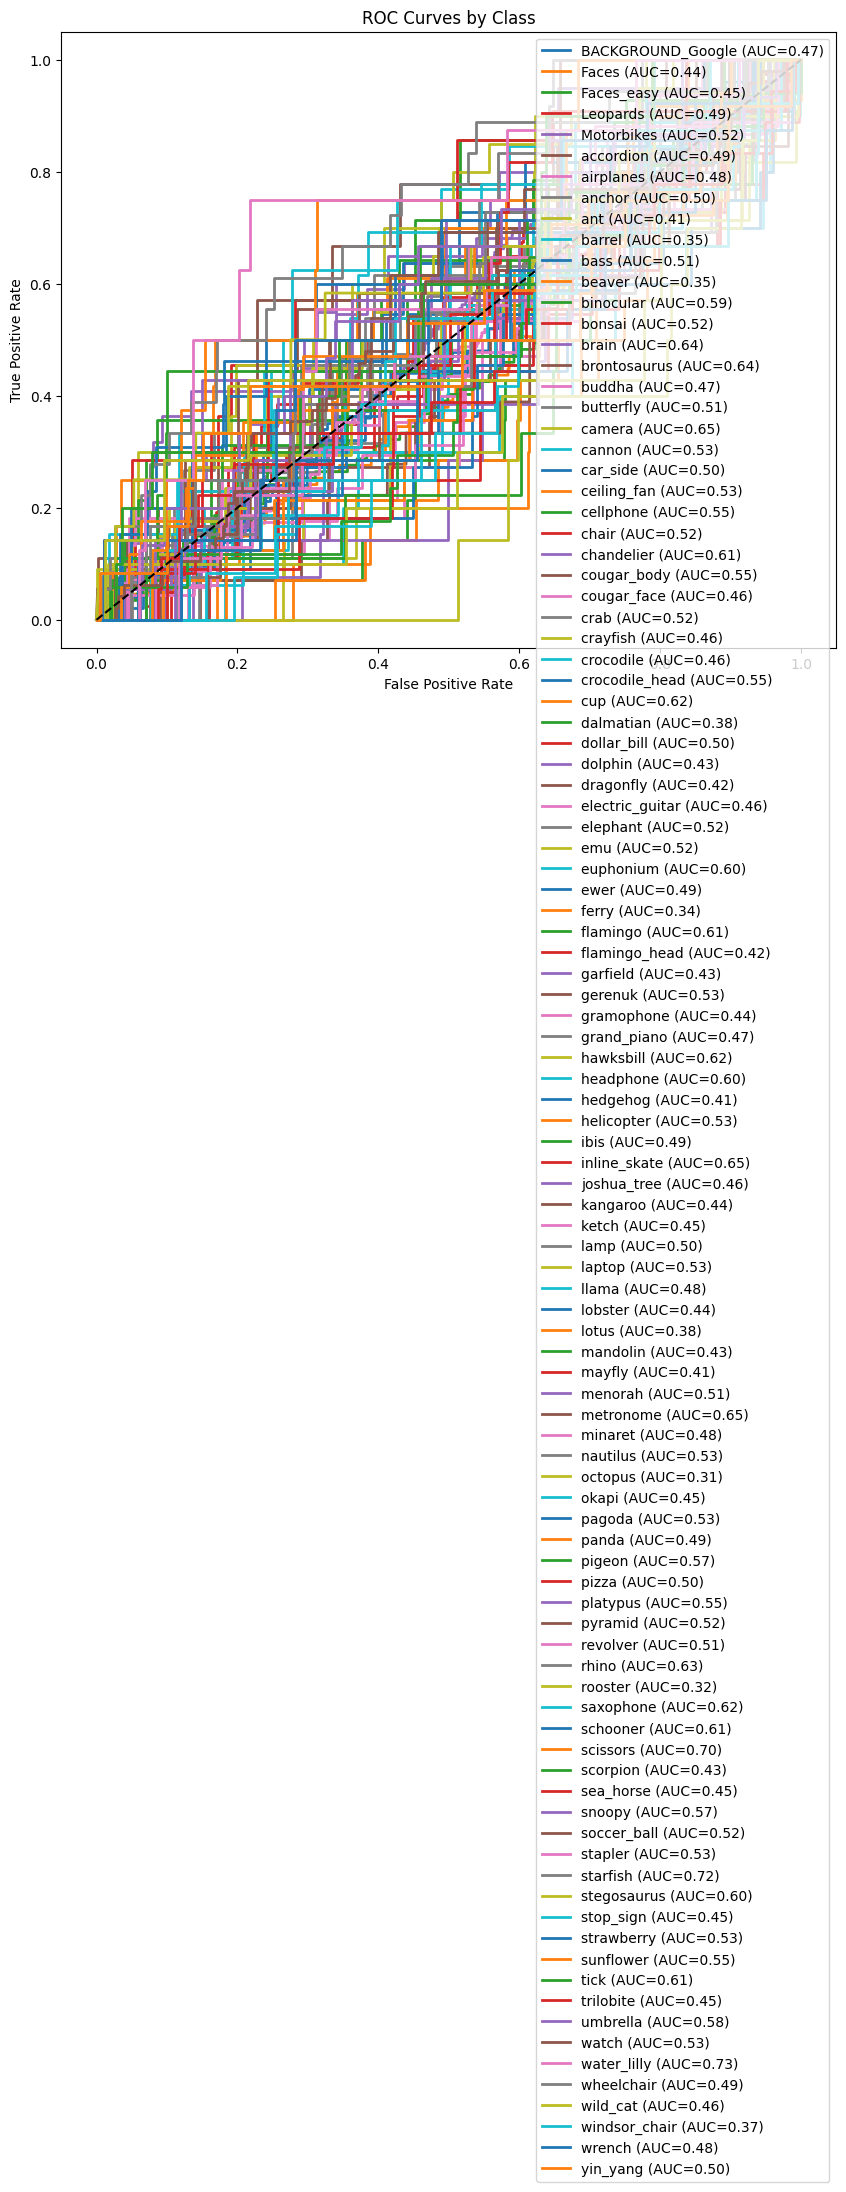

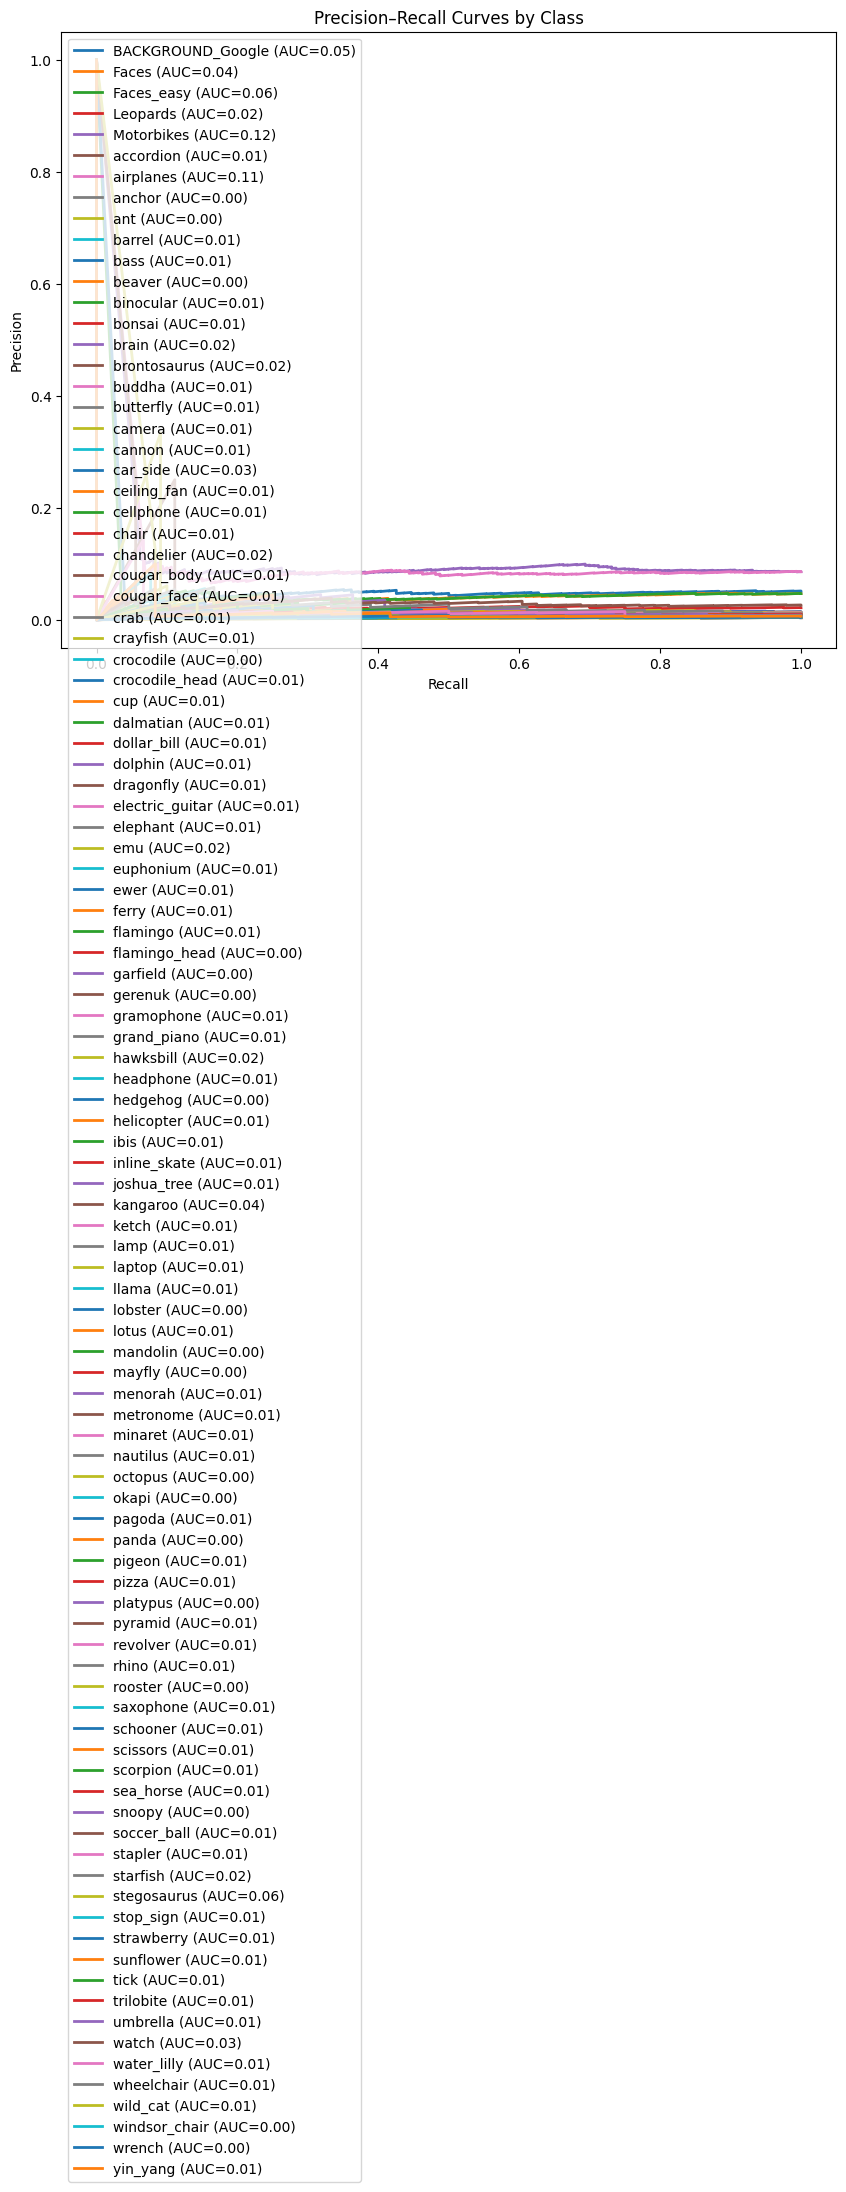

In [19]:
# ROC & PR Curves
y_true_bin = label_binarize(y_true, classes=range(len(class_labels)))
fpr, tpr, roc_auc = {}, {}, {}
precision, recall, pr_auc = {}, {}, {}
for i in range(len(class_labels)):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    pr_auc[i] = auc(recall[i], precision[i])

plt.figure(figsize=(10, 8))
for i, label in enumerate(class_labels):
    plt.plot(fpr[i], tpr[i], lw=2, label=f'{label} (AUC={roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curves by Class')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

plt.figure(figsize=(10, 8))
for i, label in enumerate(class_labels):
    plt.plot(recall[i], precision[i], lw=2, label=f'{label} (AUC={pr_auc[i]:.2f})')
plt.title('Precision–Recall Curves by Class')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step


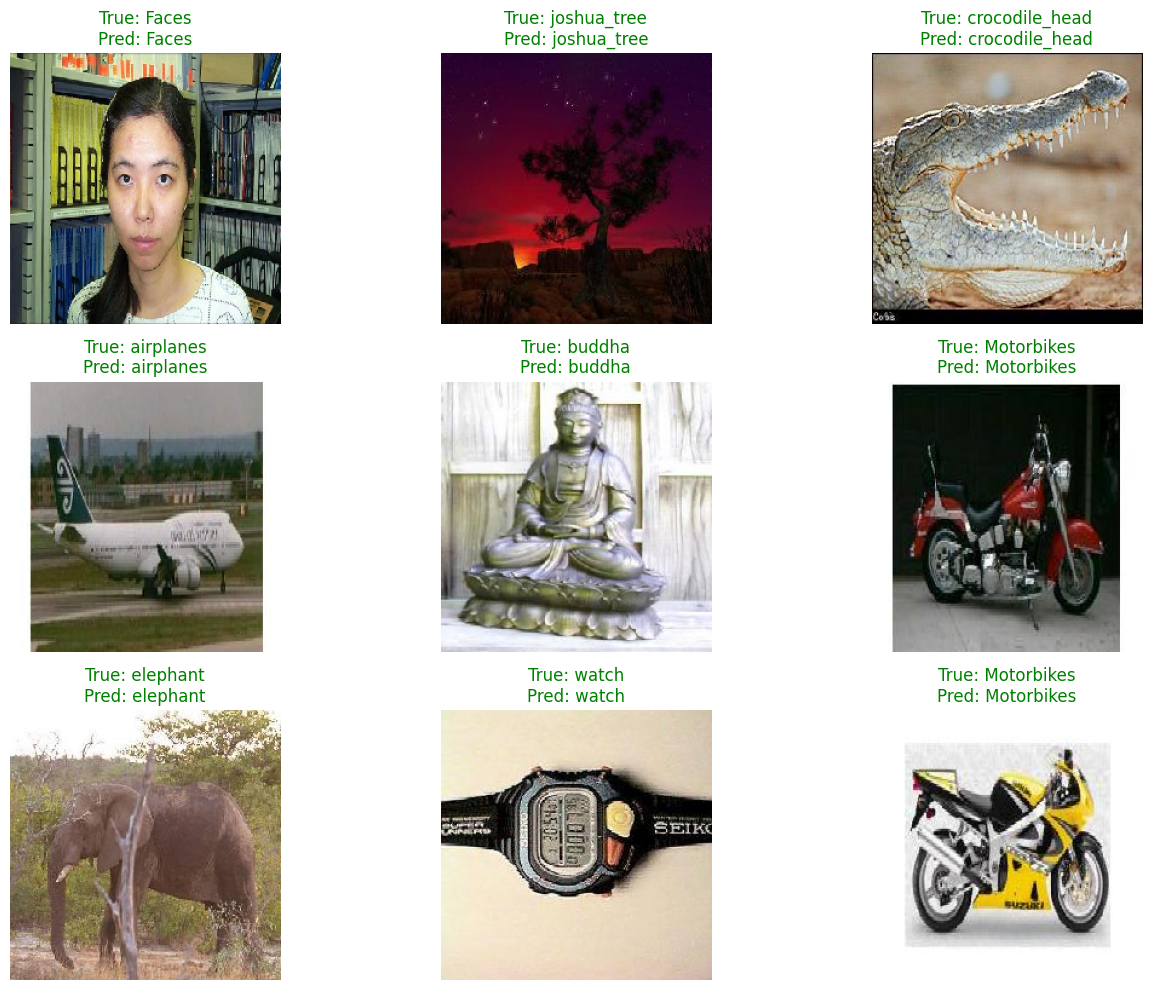

✅ All evaluation visualizations complete!


In [20]:
# STEP 🔟 — Example Predictions
x_batch, y_batch = next(val_gen)
preds = model.predict(x_batch)
pred_classes = np.argmax(preds, axis=1)
true_classes = np.argmax(y_batch, axis=1)

plt.figure(figsize=(14, 10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_batch[i])
    pred_label = class_labels[pred_classes[i]]
    true_label = class_labels[true_classes[i]]
    color = "green" if pred_label == true_label else "red"
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("✅ All evaluation visualizations complete!")

🎯 Showing ROC & PR curves for these 5 random classes: ['emu', 'crayfish', 'stapler', 'lotus', 'bass']


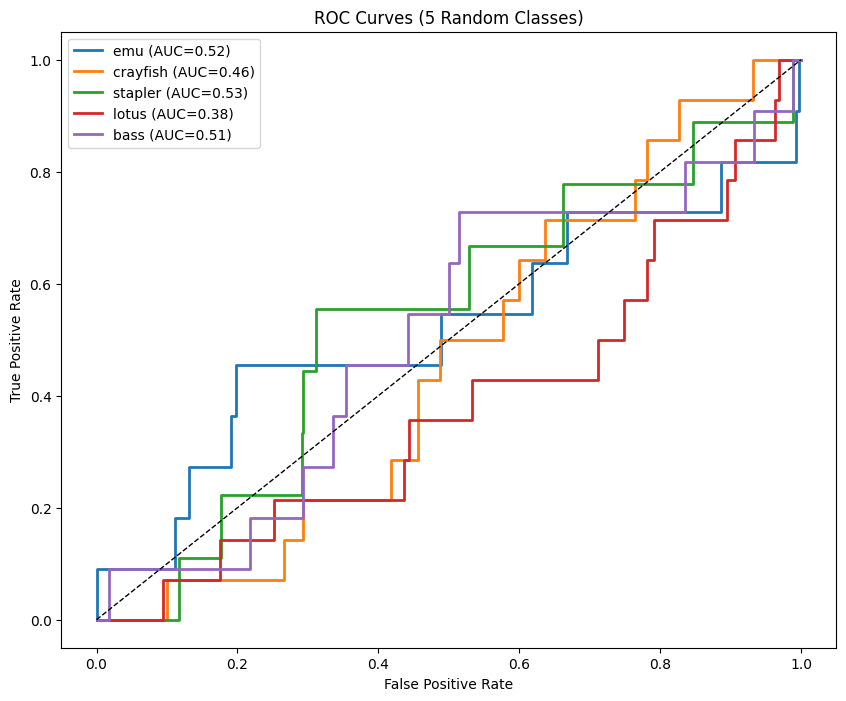

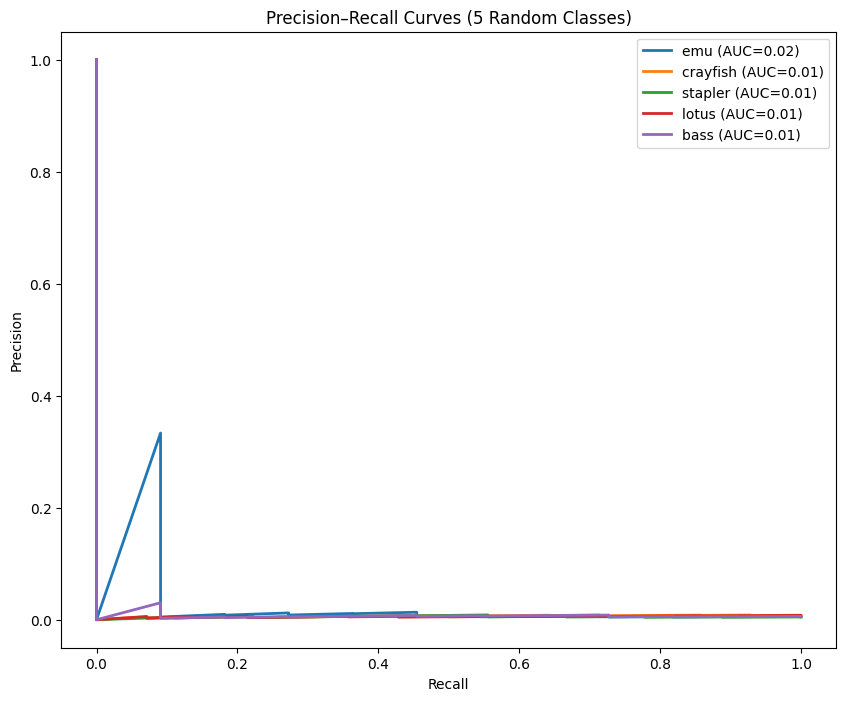

In [21]:
# --- ROC & PR Curves (show 5 random classes only) ---
import random
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# Binarize true labels for one-vs-rest computation
y_true_bin = label_binarize(y_true, classes=range(len(class_labels)))

# Randomly select 5 unique classes to visualize
random_classes = random.sample(class_labels, 5)
print(f"🎯 Showing ROC & PR curves for these 5 random classes: {random_classes}")

# Compute ROC & PR for selected classes
fpr, tpr, roc_auc = {}, {}, {}
precision, recall, pr_auc = {}, {}, {}

for label in random_classes:
    i = class_labels.index(label)
    fpr[label], tpr[label], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    precision[label], recall[label], _ = precision_recall_curve(y_true_bin[:, i], y_pred[:, i])
    roc_auc[label] = auc(fpr[label], tpr[label])
    pr_auc[label] = auc(recall[label], precision[label])

# Plot ROC Curves
plt.figure(figsize=(10, 8))
for label in random_classes:
    plt.plot(fpr[label], tpr[label], lw=2, label=f'{label} (AUC={roc_auc[label]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.title('ROC Curves (5 Random Classes)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

# Plot Precision–Recall Curves
plt.figure(figsize=(10, 8))
for label in random_classes:
    plt.plot(recall[label], precision[label], lw=2, label=f'{label} (AUC={pr_auc[label]:.2f})')
plt.title('Precision–Recall Curves (5 Random Classes)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()


🎯 Displaying ROC & PR curves for 5 random classes: ['dollar_bill', 'nautilus', 'windsor_chair', 'car_side', 'binocular']


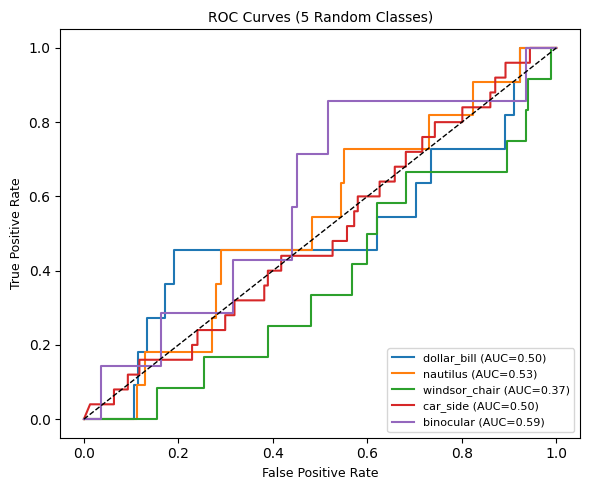

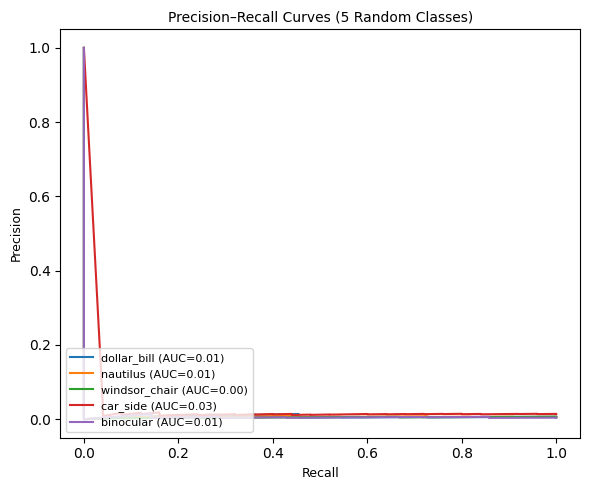

In [22]:
# --- ROC & PR Curves (compact version: 5 random classes) ---
import random
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# Binarize true labels for one-vs-rest computation
y_true_bin = label_binarize(y_true, classes=range(len(class_labels)))

# Randomly select 5 classes to display
random_classes = random.sample(class_labels, 5)
print(f"🎯 Displaying ROC & PR curves for 5 random classes: {random_classes}")

# Compute ROC & PR for the selected classes
fpr, tpr, roc_auc = {}, {}, {}
precision, recall, pr_auc = {}, {}, {}

for label in random_classes:
    i = class_labels.index(label)
    fpr[label], tpr[label], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    precision[label], recall[label], _ = precision_recall_curve(y_true_bin[:, i], y_pred[:, i])
    roc_auc[label] = auc(fpr[label], tpr[label])
    pr_auc[label] = auc(recall[label], precision[label])

# --- ROC Curves ---
plt.figure(figsize=(6, 5))  # Smaller figure
for label in random_classes:
    plt.plot(fpr[label], tpr[label], lw=1.5, label=f'{label} (AUC={roc_auc[label]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.title('ROC Curves (5 Random Classes)', fontsize=10)
plt.xlabel('False Positive Rate', fontsize=9)
plt.ylabel('True Positive Rate', fontsize=9)
plt.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

# --- Precision–Recall Curves ---
plt.figure(figsize=(6, 5))  # Smaller figure
for label in random_classes:
    plt.plot(recall[label], precision[label], lw=1.5, label=f'{label} (AUC={pr_auc[label]:.2f})')
plt.title('Precision–Recall Curves (5 Random Classes)', fontsize=10)
plt.xlabel('Recall', fontsize=9)
plt.ylabel('Precision', fontsize=9)
plt.legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()
